# 01 · Exploring the human reviews

This notebook explores the properties of the data after the cleaning process (`clean_reviews.py`).

**Goal:** check that the cleaned human reviews (label 0) are suitable before any AI reviews are generated:

1. what the cleaning removed, and whether each rule removes what it should remove,
2. how the reviews are spread over time, games and recommendation (thumbs up/down),
3. how long they are (word count),
4. known risks: reviews clustered in one part of the month, Steam Awards reviews,
5. how this collection differs from the earlier ones (v1: newest reviews 3,000 per game; v2: 30-day windows).

**Data:** `data/clean/v3/` from `scripts/collect_steam_reviews.py` (3,000 reviews per game, one random 7-day slice in every calendar month, 2015 – 29 Nov 2022) and `scripts/clean_reviews.py`. The data folder is git-ignored: raw review text is not published. This notebook saves only **aggregated** tables and plots to `results/01_explore/`, and prints only a few short example reviews.

In [1]:
import json
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# The notebook lives in notebooks/, all paths are relative to the repository root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = ROOT / "data" / "raw" / "v3"          # git-ignored, local only
CLEAN_DIR = ROOT / "data" / "clean" / "v3"      # git-ignored, local only
RESULTS_DIR = ROOT / "results" / "01_explore"   # aggregated tables and plots, safe to publish
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Optional: cleaned data of the earlier collections, for the comparison in section 6.
# Change the paths if yours are elsewhere; a missing file is simply skipped.
EARLIER = {
    "v1 (newest 3,000)": ROOT.parent / "data_Steam" / "data" / "clean_data_Claude" / "reviews_clean.csv",
    "v2 (30-day windows)": ROOT / "data" / "clean" / "v2" / "reviews_clean.csv",
}

GAMES = {
    620: "Portal 2", 105600: "Terraria", 413150: "Stardew Valley", 292030: "Witcher 3",
    367520: "Hollow Knight", 646570: "Slay the Spire", 289070: "Civilization VI",
    1145360: "Hades", 1091500: "Cyberpunk 2077", 1517290: "Battlefield 2042",
    1151340: "Fallout 76", 578080: "PUBG",
}


BLUE, INK2 = "#2a78d6", "#52514e"
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2})

In [2]:
df = pd.read_csv(CLEAN_DIR / "reviews_clean.csv")
report = json.loads((CLEAN_DIR / "cleaning_report.json").read_text(encoding="utf-8"))
dropped_examples = pd.read_csv(CLEAN_DIR / "dropped_examples.csv")

df["game"] = df["appid"].map(GAMES)
df["date"] = pd.to_datetime(df["timestamp_created"], unit="s", utc=True)
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.strftime("%Y-%m")
dropped_examples["game"] = dropped_examples["appid"].map(GAMES)

# Games ordered by their first review in our data (roughly: when they came out on Steam).
GAME_ORDER = df.groupby("game")["date"].min().sort_values().index.tolist()

print(f"{len(df):,} kept reviews from {df['game'].nunique()} games, "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")

27,691 kept reviews from 12 games, 2015-01-12 to 2022-11-25


## 1. What the cleaning removed

Counts come from `cleaning_report.json`. Rules run in this order, and a review is counted only under the **first** rule that removes it.

In [3]:
RULES = ["dropped_empty", "dropped_mostly_symbols",
         "dropped_other_language_tag", "dropped_non_english_text", "dropped_too_short",
         "dropped_duplicate"]

overview = pd.DataFrame({"reviews": [report.get(rule, 0) for rule in RULES]}, index=RULES)
overview.loc["kept"] = report["kept"]
overview["share_of_collected_%"] = (100 * overview["reviews"] / report["input"]).round(1)
overview.to_csv(RESULTS_DIR / "cleaning_overview.csv")
overview

,reviews,share_of_collected_%
dropped_empty,101,0.3
dropped_mostly_symbols,409,1.1
dropped_other_language_tag,0,0.0
dropped_non_english_text,180,0.5
dropped_too_short,6706,18.6
dropped_duplicate,913,2.5
kept,27691,76.9


Share of each game's collected reviews removed by each rule (in %). This answers why some games keep fewer reviews than others.

In [4]:
per_game = pd.DataFrame(report["dropped_per_app"]).fillna(0).astype(int)   # rows: appid, columns: rule
per_game.index = per_game.index.astype(int).map(GAMES)
per_game["kept"] = pd.Series({GAMES[int(a)]: n for a, n in report["kept_per_app"].items()})
collected = per_game.sum(axis=1)

per_game_share = (100 * per_game.div(collected, axis=0)).round(1).loc[GAME_ORDER]
per_game_share.to_csv(RESULTS_DIR / "cleaning_per_game_share.csv")
per_game_share

,dropped_duplicate,dropped_empty,dropped_mostly_symbols,dropped_non_english_text,dropped_too_short,kept
Terraria,2.1,0.2,1.3,0.2,24.7,71.6
Portal 2,4.3,0.2,1.1,0.5,20.6,73.3
Witcher 3,4.0,0.3,0.8,0.8,16.7,77.4
Stardew Valley,2.7,0.2,0.6,0.3,16.9,79.3
Civilization VI,2.7,0.4,0.9,0.5,15.4,80.0
Hollow Knight,2.5,0.2,0.8,0.4,17.0,79.2
PUBG,3.2,0.2,2.4,1.9,28.2,64.1
Slay the Spire,3.0,0.2,0.6,0.3,17.1,78.8
Hades,1.5,0.3,0.9,0.3,18.8,78.3
Fallout 76,1.8,0.5,1.0,0.3,15.0,81.5


### 1.1 Does each rule remove what it should?

A count alone does not show whether a rule removes noise or real reviews. So the cleaning script saves a random sample of 25 removed reviews per rule (seed 42) to `data/clean/v3/dropped_examples.csv`. That file contains scraped review text, so it stays local and is not published (run `clean_reviews.py` to obtain it). The table below shows the first 3 per rule, shortened; the findings after it summarise all 25 per rule, with short quoted examples.

In [5]:
def short(text, n=110):
    if pd.isna(text) or str(text).strip() == "":
        return "(empty)"
    text = str(text)
    return text if len(text) <= n else text[:n] + "…"

shown = dropped_examples.groupby("rule").head(3)
shown.assign(text=shown["text"].map(short))[["rule", "game", "text"]]

,rule,game,text
0,dropped_duplicate,PUBG,very good game
1,dropped_duplicate,Hades,VERY GOOD GAME
2,dropped_duplicate,Terraria,This is the best game ever!!!!!
25,dropped_empty,Hades,(empty)
26,dropped_empty,Portal 2,(empty)
27,dropped_empty,PUBG,(empty)
50,dropped_mostly_symbols,Terraria,/
51,dropped_mostly_symbols,Portal 2,.
52,dropped_mostly_symbols,Witcher 3,.
75,dropped_non_english_text,PUBG,我叼你妈的什么游戏？开挂的一大堆，不少网骗在这里忽悠自己不是国人，盗号的也有，还有那些不想打...


**What the sample of removed reviews showed** (all 25 per rule read on 17 Nov 2026; counts are for all 36,000 collected reviews)

| Rule | What it removes | Removed | What the 25 sampled reviews were | Verdict |
| --- | --- | --- | --- | --- |
| Fewer than 3 words | reviews too short for any classifier | 6,706 | All have 1–2 words. Many are clear opinions: "GOTY", "10/10", "Phenomenal.", "love PUBG". A few are gibberish ("ygudhyuvgi") or another language ("Muy bueno"). | Correct by definition, but it removes real opinions: the detector cannot judge reviews this short. **Reported as a limit.** |
| Duplicate | the same text as an earlier review, ignoring case, spacing and punctuation | 913 | Mostly generic phrases ("very good game", "best game ever"), memes and quotes from the games ("just one .... more ... turn ..."), one sentence copied from a press review, and one fully copied checklist template ("---{ Graphics }--- ☑ You forget what reality is ☐ Beautiful …"). | Correct. Keeps identical texts out of both the training and the test set (see 1.2). |
| Mostly symbols | texts where more than half of the visible characters are not letters or digits | 409 | Mostly ".", ":)", "👍", "..." and pictures drawn with braille or block characters, sometimes with a meme caption ("average Hades enjoyer" + picture). **One loss:** a ~70-word genuine Cyberpunk review followed by a large braille picture, removed because the picture has more characters than the text. | Correct, with one rare loss. |
| Non-English text | reviews tagged English whose letters are less than 90% plain Latin | 180 | Chinese, Japanese, Korean, Russian, Arabic, Hebrew, Thai, Polish. Mixed reviews (Arabic or Chinese followed by an English translation) are removed on purpose. **One loss:** an English review written in Unicode small capitals ("Bᴇsᴛ Rᴏɢᴜᴇʟɪᴋᴇ. Gʀᴇᴀᴛ sᴏᴜɴᴅᴛʀᴀᴄᴋ…"), which the NFKC normalisation does not turn into plain letters. | Correct, with one rare loss. |
| Empty | reviews with no text | 101 | All 25 empty. | Correct. |

**Conclusion:** 2 of the 125 sampled removals (1.6%) were genuine English reviews, both rare edge cases: text followed by a picture, and text in small capitals. Fixing them would need special-case rules for very few reviews, so we keep the rules and report these cases as known limits. The rule "same character 10+ times" is not in the table: it was removed after the same check showed that it mostly removed genuine reviews (see 1.3 and the failure journal).

### 1.2 Duplicates: copies inside one game, or the same phrase across games?

The duplicate check runs across **all** games and keeps the first copy, in the order the files are read. So we re-run the cleaning code from `scripts/clean_reviews.py` (the same functions, not a copy) to get every removed duplicate, and look up which game holds the kept copy.

In [6]:
sys.path.insert(0, str(ROOT / "scripts"))
from clean_reviews import load_raw, clean, duplicate_key

raw = list(load_raw(RAW_DIR))
_, _, _, dropped_all = clean(raw, min_words=report["min_words"])

kept_copy_game = {duplicate_key(text): game for text, game in zip(df["text"], df["game"])}
dups = pd.DataFrame(dropped_all["dropped_duplicate"])
dups["game"] = dups["appid"].map(GAMES)
dups["kept_copy_game"] = dups["text"].map(lambda t: kept_copy_game.get(duplicate_key(t)))
dups["same_game"] = dups["game"] == dups["kept_copy_game"]

print(f"{len(dups):,} duplicates removed; "
      f"{dups['same_game'].mean():.0%} copy a review of the same game, "
      f"{1 - dups['same_game'].mean():.0%} copy a review of another game")
print("\nMost repeated texts (lowercased):")
print(dups["text"].str.lower().map(short).value_counts().head(10).to_string())

913 duplicates removed; 21% copy a review of the same game, 79% copy a review of another game

Most repeated texts (lowercased):
text
best game ever          42
very good game          27
love this game          18
i love it               14
i like it               14
best game ever.         13
its pretty good         11
best game ever!          9
best game ever made.     9
it is good               8


**Interpretation:** most removed duplicates (79%) are not copy-paste / spam but the same short phrase written for different games (e.g., "best game ever" 42×). We still remove them: an identical text with the same label in both the training and the test set would make the test too easy, and the model could score by memorising these phrases. On the other hand, some genuine reviews are lost, and which game loses them depends on the order the files are read (the first copy is kept), so per-game duplicate counts are partly an artefact. Later: check whether AI reviews repeat the same stock phrases as humans.

### 1.3 Check of the removed rule "same character 10+ times"

The rule was removed on 17 Nov (see the failure journal) because it removed genuine reviews with emphasis. These are the kept reviews it would have removed: they should be real reviews, and no ASCII art should be among them (art is caught by "mostly symbols").

In [7]:
REPEATED = re.compile(r"(.)\1{9,}")
would_drop = df[df["text"].str.contains(REPEATED)]
print(f"{len(would_drop):,} kept reviews contain a character repeated 10+ times "
      f"({len(would_drop) / len(df):.1%} of kept reviews)")
would_drop.sample(min(8, len(would_drop)), random_state=1).assign(text=lambda d: d["text"].map(short))[["game", "voted_up", "text"]]

C:\Users\simon\AppData\Local\Temp\ipykernel_10804\3542926769.py:2: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  would_drop = df[df["text"].str.contains(REPEATED)]


152 kept reviews contain a character repeated 10+ times (0.5% of kept reviews)


,game,voted_up,text
11370,Battlefield 2042,False,"i had hope, but hope is a joke with this game ..."
8176,Fallout 76,True,guns go brrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrr...
14258,Witcher 3,True,"A long time ago, I bought the Witcher 2 cheap...."
23609,Portal 2,True,"I know this game. It's a great game. No, an aw..."
7838,Fallout 76,False,HOW GOD DAMN HARD IS IT TO MAKE STUFF WORK PRO...
21669,PUBG,False,Update - still too many cheats to recommend th...
20372,Stardew Valley,True,It eases my old tired bones. I am not.... a ga...
3110,Cyberpunk 2077,True,This game sooooooooooooooooooooooooooo good no...


**Interpretation:** the 152 reviews the old rule would have removed are genuine, often emotional reviews ("guns go brrrrrr…", "HOW GOD DAMN HARD IS IT…"), and no ASCII art got through, because "mostly symbols" catches it. Removing the rule keeps the human class as messy as real reviews are; dropping these reviews would have made human text look tidier and closer to AI text than it really is.

## 2. Spread over time

The collection asked for the same number of reviews from every 30-day window in which a game had reviews, so every game should be roughly flat over the years after it came out. Cleaning removes a different share in different periods, so the counts are not exactly equal.

In [8]:
by_year = pd.crosstab(df["game"], df["year"], margins=True, margins_name="Total").loc[GAME_ORDER + ["Total"]]
by_year.to_csv(RESULTS_DIR / "reviews_by_game_and_year.csv")
by_year

year,2015,2016,2017,2018,2019,2020,2021,2022,Total
game,,,,,,,,,
Terraria,332,312,311,315,265,211,207,194,2147
Portal 2,326,328,314,297,279,223,228,203,2198
Witcher 3,207,364,349,326,297,280,267,231,2321
Stardew Valley,0,335,392,379,356,340,311,266,2379
Civilization VI,0,78,469,447,408,358,344,297,2401
Hollow Knight,0,0,420,463,437,390,343,322,2375
PUBG,0,0,362,407,367,272,274,241,1923
Slay the Spire,0,0,87,521,463,459,433,400,2363
Hades,0,0,0,0,71,864,741,673,2349


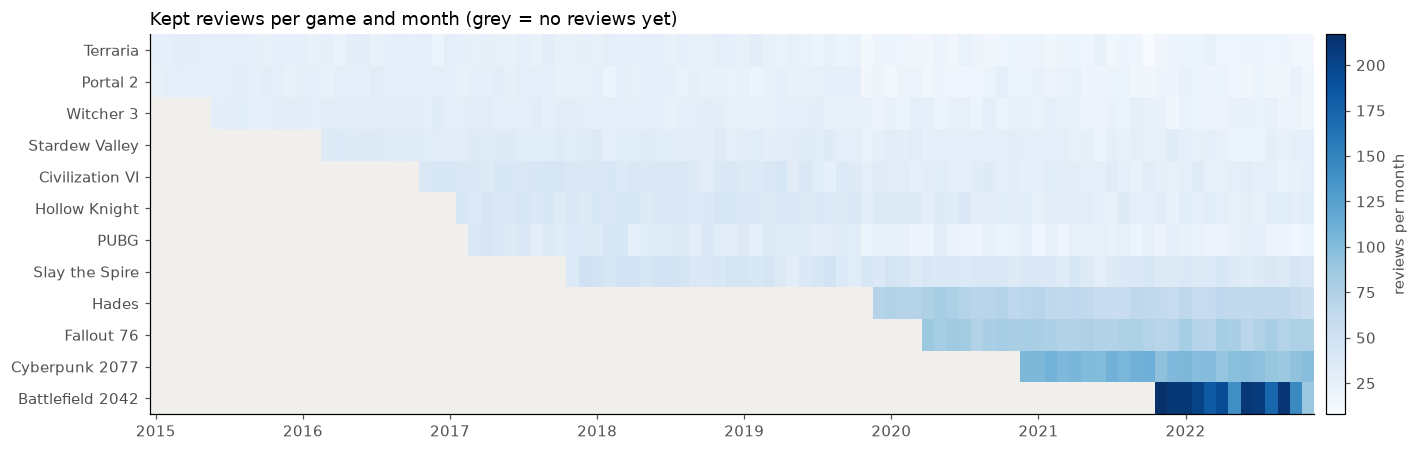

In [9]:
by_month = pd.crosstab(df["game"], df["month"]).reindex(GAME_ORDER)
by_month.to_csv(RESULTS_DIR / "reviews_by_game_and_month.csv")

fig, ax = plt.subplots(figsize=(13, 4.2))
data = np.ma.masked_equal(by_month.values, 0)
cmap = plt.get_cmap("Blues").copy()
cmap.set_bad("#f0efec")
im = ax.imshow(data, aspect="auto", cmap=cmap, interpolation="nearest")
ax.set_yticks(range(len(GAME_ORDER)), GAME_ORDER)
january = [i for i, m in enumerate(by_month.columns) if m.endswith("-01")]
ax.set_xticks(january, [by_month.columns[i][:4] for i in january])
ax.set_title("Kept reviews per game and month (grey = no reviews yet)", loc="left")
fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01, label="reviews per month")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "reviews_by_game_and_month.png", dpi=150)
plt.show()

**Interpretation:** every game is covered from 2015 (or from its release if the game was published after the lower bound of the window) to Nov 2022, so the model cannot rely on topics of one short period (a sale, a patch, Steam awards...). Two consequences: (1) year and game are linked: 2015–2016 reviews come only from the five oldest games, so results by year must be read together with results by game; (2) the human reviews are 4–11 years older than the AI reviews (2026), so the model could partly learn "old vs new language". We will check errors by year of the human review.

### 2.1 Is any part of the month favoured?

v2 took the newest ~100 reviews of every 30-day window, so 77% of its reviews came from the last 3 days of a window. v3 asks Steam for one random 7-day slice per month instead. If that works, every day of the month and of the week should be about equally common (days 29–31 are rarer because not every month has them).

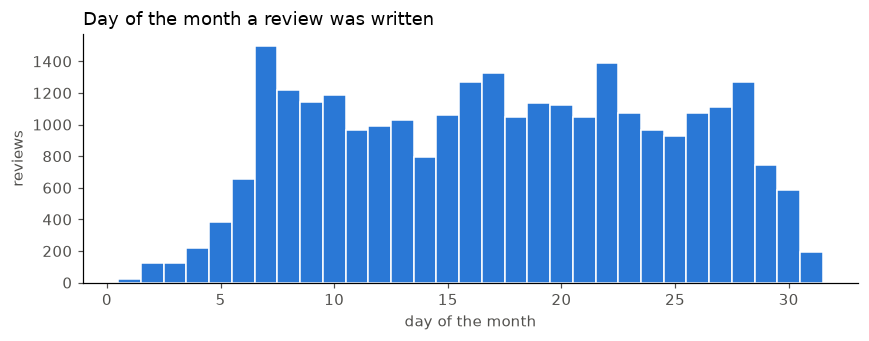

Share by part of the month (about 33% / 33% / 35% if even):
date
days 1-10     23.7
days 11-20    38.8
days 21-31    37.5

Share by day of the week (about 14.3% each if even):
date
Thursday     15.6
Wednesday    14.8
Monday       14.3
Sunday       14.3
Saturday     13.9
Tuesday      13.7
Friday       13.4


In [10]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(df["date"].dt.day, bins=range(1, 33), color=BLUE, edgecolor="white", align="left")
ax.set_xlabel("day of the month")
ax.set_ylabel("reviews")
ax.set_title("Day of the month a review was written", loc="left")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "day_of_month.png", dpi=150)
plt.show()

part_of_month = pd.cut(df["date"].dt.day, [0, 10, 20, 31], labels=["days 1-10", "days 11-20", "days 21-31"])
print("Share by part of the month (about 33% / 33% / 35% if even):")
print((100 * part_of_month.value_counts(normalize=True).sort_index()).round(1).to_string())
print("\nShare by day of the week (about 14.3% each if even):")
print((100 * df["date"].dt.day_name().value_counts(normalize=True)).round(1).to_string())

**Interpretation:** the end-of-window clustering of v2 (check repository history to see v2) is gone (days 21–31: 48.4% → 37.5%) and days of the week are even. Days 1–10 are still underrepresented (23.7% instead of ~33%) because the 7-day slice must fit inside the month and Steam returns the newest reviews of the slice first. We keep this as a known limit: there is no reason to expect that reviews from the start of a month are written differently, and fixing it would need another collection run.

## 3. Recommendation (thumbs up / down)

AI reviews will be matched on recommendation, so both classes get the same share of positive reviews. What matters here is how many negative reviews there are and which games they come from.

In [11]:
sentiment = df.groupby("game").agg(reviews=("voted_up", "size"),
                                   positive_share=("voted_up", "mean"),
                                   negative=("voted_up", lambda s: int((~s.astype(bool)).sum())))
sentiment["positive_share"] = sentiment["positive_share"].round(3)
sentiment["share_of_all_negative_%"] = (100 * sentiment["negative"] / sentiment["negative"].sum()).round(1)
sentiment = sentiment.loc[GAME_ORDER]
sentiment.to_csv(RESULTS_DIR / "sentiment_by_game.csv")

print(f"Positive overall: {df['voted_up'].mean():.1%}, negative reviews: {int((~df['voted_up'].astype(bool)).sum()):,}")
sentiment

Positive overall: 83.2%, negative reviews: 4,646


,reviews,positive_share,negative,share_of_all_negative_%
game,,,,
Terraria,2147,0.969,66,1.4
Portal 2,2198,0.983,37,0.8
Witcher 3,2321,0.966,78,1.7
Stardew Valley,2379,0.983,40,0.9
Civilization VI,2401,0.699,723,15.6
Hollow Knight,2375,0.964,86,1.9
PUBG,1923,0.564,839,18.1
Slay the Spire,2363,0.965,83,1.8
Hades,2349,0.989,27,0.6


In [12]:
positive_by_year = df.pivot_table(index="game", columns="year", values="voted_up", aggfunc="mean").round(2).loc[GAME_ORDER]
positive_by_year.to_csv(RESULTS_DIR / "positive_share_by_game_and_year.csv")
positive_by_year

year,2015,2016,2017,2018,2019,2020,2021,2022
game,,,,,,,,
Terraria,0.97,0.96,0.97,0.95,0.97,0.99,0.98,0.96
Portal 2,0.98,0.98,0.98,0.98,0.98,0.99,0.98,1.00
Witcher 3,0.95,0.98,0.98,0.96,0.96,0.98,0.96,0.97
Stardew Valley,NaN,0.98,0.99,0.98,0.97,0.99,0.99,1.00
Civilization VI,NaN,0.60,0.53,0.58,0.68,0.87,0.82,0.84
Hollow Knight,NaN,NaN,0.96,0.95,0.96,0.97,0.98,0.97
PUBG,NaN,NaN,0.69,0.40,0.54,0.62,0.58,0.61
Slay the Spire,NaN,NaN,0.98,0.97,0.95,0.98,0.97,0.94
Hades,NaN,NaN,NaN,NaN,1.00,1.00,0.98,0.98


**Interpretation:** negative reviews (16.8%) are concentrated in a few games, and the share of positive reviews changes over time within a game (e.g. Civilization VI 0.56–0.58 in 2016–2017, 0.86 in 2020), which follows the game's history rather than a rule. Because AI reviews are generated per human review with the same game and recommendation, neither the recommendation nor the game can give the class away. Results will still be reported separately for positive and negative reviews, since the model sees far fewer negative examples.

## 4. Length

Word counts use the same definition as the cleaning script (letters and apostrophes; numbers do not count). Reviews under 3 words were removed.

count    27691.0
mean        51.0
std        102.1
min          3.0
10%          4.0
25%          8.0
50%         19.0
75%         50.0
90%        119.0
99%        509.1
max       1491.0


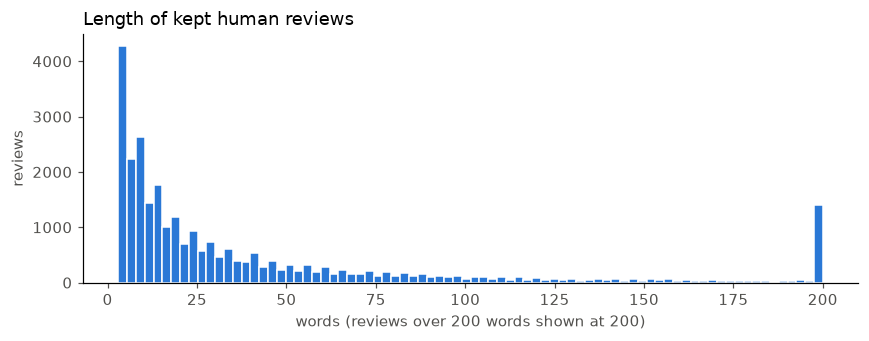

In [13]:
print(df["word_count"].describe(percentiles=[.1, .25, .5, .75, .9, .99]).round(1).to_string())

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(df["word_count"].clip(upper=200), bins=80, color=BLUE, edgecolor="white")
ax.set_xlabel("words (reviews over 200 words shown at 200)")
ax.set_ylabel("reviews")
ax.set_title("Length of kept human reviews", loc="left")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "length_histogram.png", dpi=150)
plt.show()

In [14]:
length = pd.DataFrame({
    "median_words": df.groupby("game")["word_count"].median(),
    "median_words_positive": df[df["voted_up"].astype(bool)].groupby("game")["word_count"].median(),
    "median_words_negative": df[~df["voted_up"].astype(bool)].groupby("game")["word_count"].median(),
}).loc[GAME_ORDER]
length.to_csv(RESULTS_DIR / "length_by_game.csv")

print("Median words by year:")
print(df.groupby("year")["word_count"].median().to_string())
length

Median words by year:
year
2015    21.0
2016    23.0
2017    26.0
2018    24.0
2019    19.0
2020    17.0
2021    17.0
2022    16.0


,median_words,median_words_positive,median_words_negative
game,,,
Terraria,13.0,13.0,13.0
Portal 2,14.0,14.0,17.0
Witcher 3,17.0,16.0,52.0
Stardew Valley,20.0,19.0,28.5
Civilization VI,24.0,18.0,43.0
Hollow Knight,23.0,22.0,66.0
PUBG,14.0,11.0,19.0
Slay the Spire,19.0,18.0,57.0
Hades,18.0,18.0,136.0


**Interpretation:** length must not give the class away, so each AI review gets the word count of its human pair, and this matters separately for positive and negative reviews (negatives are longer in most games). The long tail (1% over 509 words, max 1,491) is expensive to generate and rare; we will decide on an upper limit when choosing the sample for AI generation and report it. Reviews got shorter over time (median 26 words in 2017, 16 in 2022), another reason to check errors by year.

## 5. Steam Awards reviews

The first collection jumped on 22 Nov 2022, likely because of the Steam Autumn Sale and Steam Awards nominations ("It won labour of love for a reason"). These are real human reviews, so they stay in the data; we only check that they are not a large share.

In [15]:
AWARD = re.compile(r"steam award|labou?r of love|nominat", re.IGNORECASE)
df["mentions_award"] = df["text"].str.contains(AWARD)

print(f"Reviews mentioning the awards: {df['mentions_award'].sum():,} ({df['mentions_award'].mean():.2%})")
print("\nShare by calendar month (%), nominations run in late November:")
print((100 * df.groupby(df["date"].dt.month)["mentions_award"].mean()).round(2).to_string())

Reviews mentioning the awards: 38 (0.14%)

Share by calendar month (%), nominations run in late November:
date
1     0.18
2     0.09
3     0.18
4     0.17
5     0.04
6     0.17
7     0.13
8     0.13
9     0.13
10    0.04
11    0.29
12    0.09


**Interpretation:** 0.14% of reviews mention the awards and there is no clear November peak, so award-driven reviews do not shape the data. No action needed.

## 6. Earlier collections vs this one

v1 took the newest 3,000 reviews per game in one window; v2 used 30-day windows; v3 uses a random 7-day slice per month. v1 and v2 were cleaned with the old rules (including "same character 10+ times"), so their counts are not fully comparable. Missing files are skipped.

In [16]:
def describe(d):
    date = pd.to_datetime(d["timestamp_created"], unit="s", utc=True)
    return pd.Series({
        "kept reviews": len(d),
        "first review": f"{date.min():%Y-%m-%d}",
        "last review": f"{date.max():%Y-%m-%d}",
        "share from 22-29 Nov 2022": f"{(date >= pd.Timestamp('2022-11-22', tz='UTC')).mean():.1%}",
        "share from days 21-31 of a month": f"{(date.dt.day >= 21).mean():.1%}",
        "median words": d["word_count"].median(),
        "positive share": f"{d['voted_up'].mean():.1%}",
        "negative reviews": int((~d["voted_up"].astype(bool)).sum()),
    })

columns = {name: describe(pd.read_csv(path)) for name, path in EARLIER.items() if path.exists()}
columns["v3 (7-day slice per month)"] = describe(df)
comparison = pd.DataFrame(columns)
comparison.to_csv(RESULTS_DIR / "collections_compared.csv")
comparison

,"v1 (newest 3,000)",v2 (30-day windows),v3 (7-day slice per month)
kept reviews,24296,27292,27691
first review,2022-07-08,2015-01-28,2015-01-12
last review,2022-11-29,2022-11-29,2022-11-25
share from 22-29 Nov 2022,39.7%,2.1%,0.6%
share from days 21-31 of a month,58.2%,48.4%,37.5%
median words,13.0,19.0,19.0
positive share,86.7%,84.1%,83.2%
negative reviews,3220,4343,4646


**Interpretation:** the collection method changed the data more than expected: the first collection had shorter reviews (median 13 vs 19 words), more positive ones (86.7% vs 83.2%) and 40% of them from a single week. A detector trained on it would have learned from one season of reviews. This is the main reason the human data were collected three times (see failure journal, 17 Nov).

## 7. Summary

- **Cleaning:** 27,691 of 36,000 collected reviews kept (76.9%). Most removals are reviews under 3 words (6,706, 18.6%); PUBG loses the most (64.1% kept) because of short, symbol-only and non-English reviews. The removed rule "same character 10+ times" would have removed 152 kept reviews (0.5%), all genuine reviews with emphasis in the sample (section 1.3).
- **Duplicates:** 913 removed; 79% repeat a generic phrase from another game ("best game ever" 42×), 21% copy a review of the same game.
- **Time spread:** every game has reviews in every month from its release to Nov 2022; only 0.6% of reviews are from 22–29 Nov 2022 (39.7% in the first collection).
- **Part of the month:** days of the week are even (13.4–15.6%), but days 1–10 of a month hold 23.7% of reviews instead of ~33%, because the 7-day slice must fit inside the month and Steam returns the newest reviews of the slice first. Kept as a known limit.
- **Recommendation:** 83.2% positive, 4,646 negative reviews; most negatives come from Battlefield 2042, PUBG, Civilization VI and Fallout 76.
- **Length:** median 19 words; negative reviews are longer than positive ones in most games; reviews got shorter over time (median 26 words in 2017, 16 in 2022). AI reviews must be matched on length separately for positive and negative reviews.
- **Steam Awards:** 38 reviews (0.14%) mention them; no late-November peak.